In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../worm-control/src'))
from utils_worm_control import read_utils as read_utils_control

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils
from models import model_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

<module 'utils.analysis_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/analysis_utils.py'>

In [3]:
organism = 'worm'

ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
manual = False
full = False

save = True

In [4]:
file_ids = [19]

In [5]:
filenames = analysis_utils.read_filenames(organism, file_ids)

model_path = read_utils.get_model_path()

metadata = (filenames, model_path, model_variant, data_variant, manual, full)

In [6]:
((boms_spn, _, _, _, _, _, _),
 (hgms_spn, _, _, _, _, _, _)) = analysis_utils.read_predictionss(*metadata)

In [7]:
neuron_scores = analysis_utils.assemble_scores(boms_spn, hgms_spn)

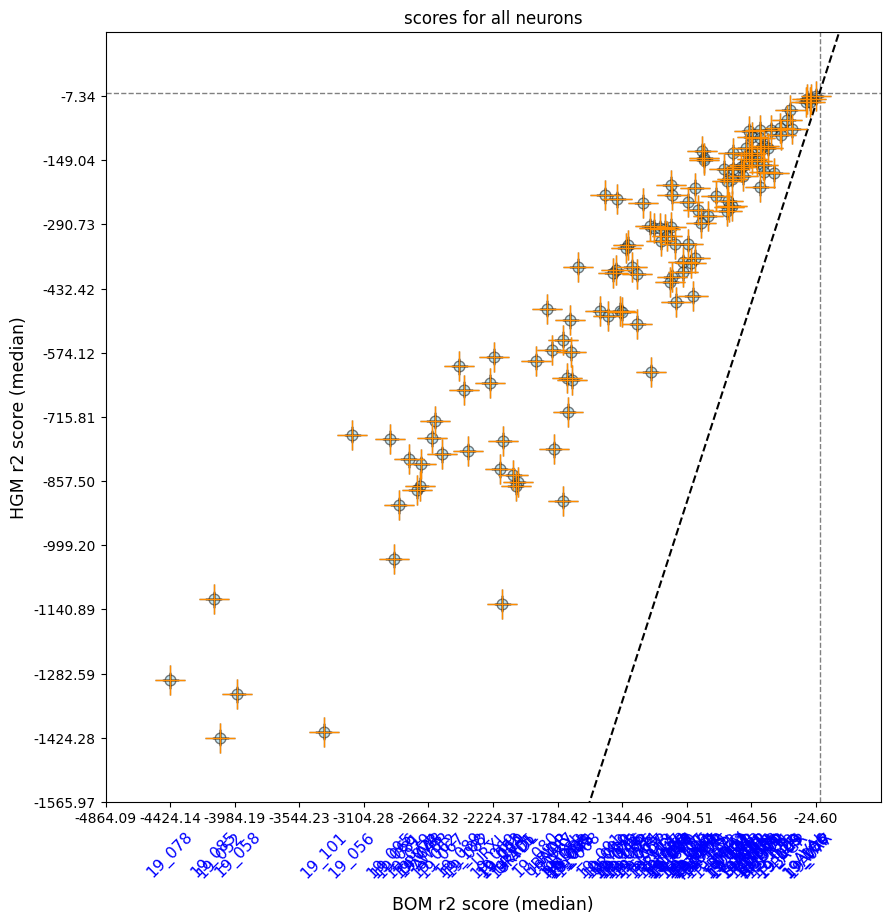

In [8]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=None, force_medians=True,
	save_path=f'../../out/plots/scores/{model_variant}_scores' if save else None
)

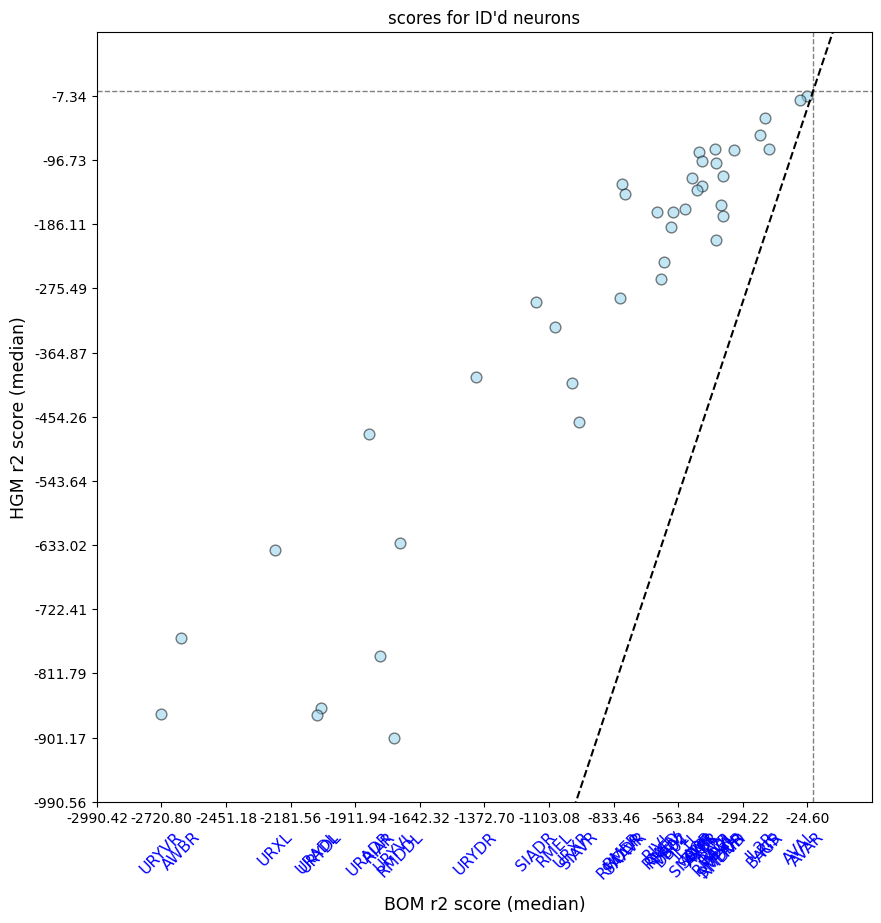

In [9]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()}, None,
	title='scores for ID\'d neurons', limits=None
)

# GFP control

In [10]:
file_ids_gfp = [2, 3]

filenames_gfp = analysis_utils.read_filenames(organism, file_ids_gfp, data_variant='gfp')
metadata_gfp = (filenames_gfp, model_path, model_variant, 'gfp', manual, full)

((boms_spn_gfp, _, _, _, _, _, _),
 (hgms_spn_gfp, _, _, _, _, _, _)) = analysis_utils.read_predictionss(filenames_gfp, model_path, model_variant, 'gfp', manual, full)
neuron_scores_gfp = analysis_utils.assemble_scores(boms_spn_gfp, hgms_spn_gfp)

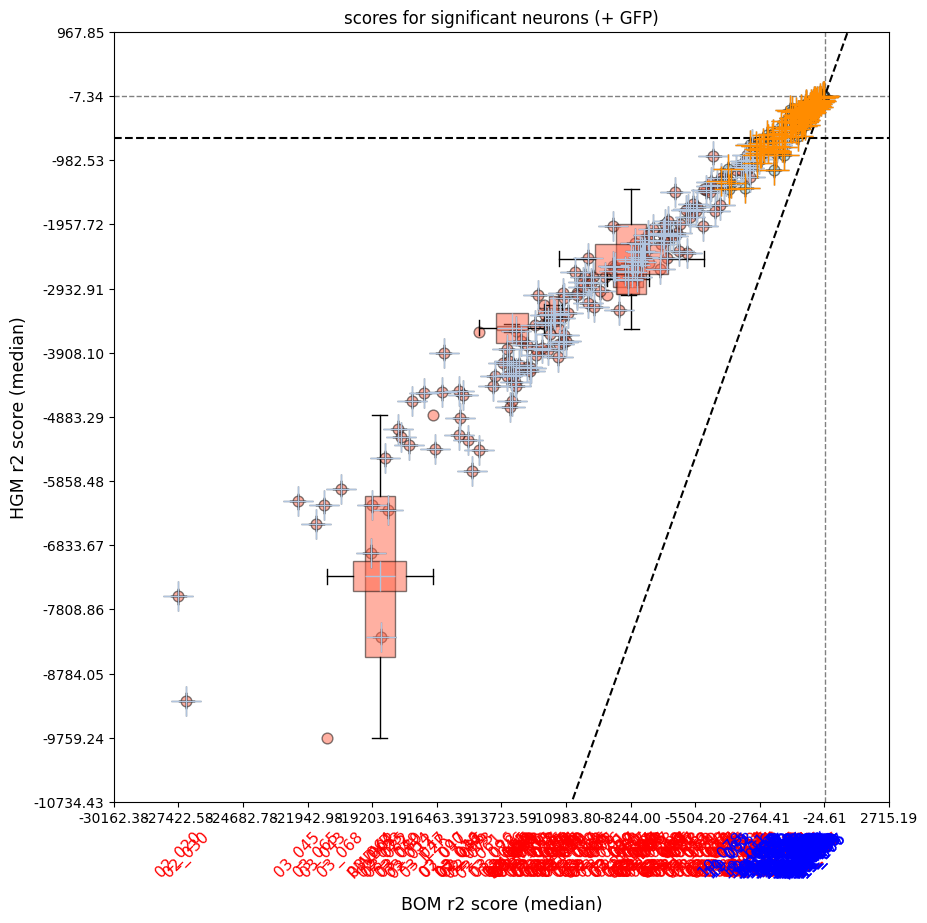

In [11]:
plot_utils.plot_performance_plot(
	neuron_scores, neuron_scores_gfp,
	title='scores for significant neurons (+ GFP)', limits=None, force_medians=True, control_cutoff=False,
)

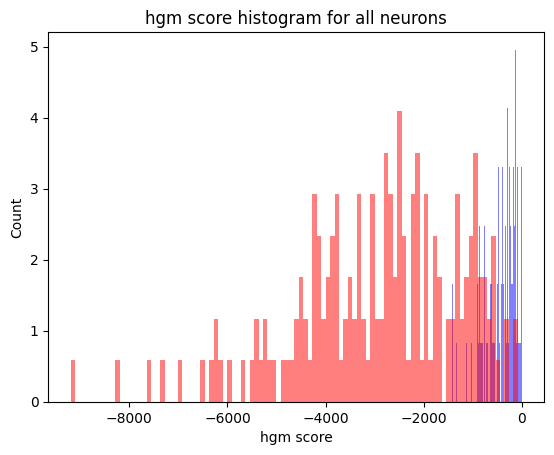

In [12]:
plot_utils.plot_performance_histogram(neuron_scores,
									  neuron_scores_gfp,
									  bins=100,
									  title='hgm score histogram for all neurons')

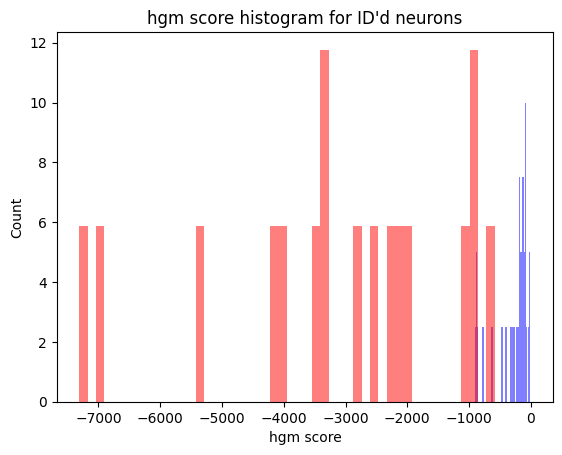

In [13]:
plot_utils.plot_performance_histogram({key: neuron_scores[key] for key in neuron_scores if not key[0].isdigit()},
									  {key: neuron_scores_gfp[key] for key in neuron_scores_gfp if not key[0].isdigit()},
									  bins=50,
									  title='hgm score histogram for ID\'d neurons')

In [14]:
threshold_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)
threshold_bom_gfp = np.quantile(np.concatenate([pair[0] for pair in neuron_scores_gfp.values()]), 0.95)
threshold_bom_gfp = np.array(0)

neuron_scores_hgm_sig = list(reversed(sorted({key: value for key, value in neuron_scores.items() if np.median(value[1].reshape(-1, 1)) > threshold_hgm_gfp and np.median(value[0].reshape(-1, 1)) > threshold_bom_gfp}.items(), key=lambda x: np.median(x[1][1]))))
neuron_scores_hgm_sig_labels = list([val[0] for val in neuron_scores_hgm_sig])

print('\n'.join([f'NEURON: {key},\t\tHGMSCR: {np.median(val[1]):.4f}' for key, val in neuron_scores_hgm_sig if not key[0].isdigit()]))

In [ ]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels}, None,
	title='scores for significant neurons', limits=None, force_medians=True
)

In [ ]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels if not key[0].isdigit()}, None,
	title='scores for significant ID\'d neurons', limits=None
)

In [ ]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels},
	title='score improvements for significant neurons', limits=None, force_medians=True
)

In [ ]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels if not key[0].isdigit()}, None,
	title='score improvements for significant ID\'d neurons', limits=None
)

In [ ]:
neuron_impros_hgm_sig = list(reversed(sorted(neuron_scores_hgm_sig, key=lambda x: np.median(x[1][1] - x[1][0]))))
neuron_impros_hgm_rel_labels = list([val[0] for val in neuron_impros_hgm_sig])

print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in neuron_impros_hgm_sig if not key[0].isdigit()]))

In [ ]:
print('Neuron names for copying:')
print(', '.join([f'\'{label}\'' for label in neuron_impros_hgm_rel_labels if not label[0].isdigit()]))

# shuffle control

In [16]:
scores_per_shuffle = list()
for shuffle_id in range(100):
	scores_per_dataset = list()
	for filename in filenames:
		((bom_spn, _, _, _, _, _, _),
		 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(filename, read_utils_control.get_model_path(shuffle_id), model_variant, manual=False)
		scores_per_dataset.append((bom_spn, hgm_spn))
	bom_spns, hgm_spns = zip(*scores_per_dataset)
	scores_per_shuffle.append([bom_spns, hgm_spns])

neuron_scores_per_shuffle = [analysis_utils.assemble_scores(*scores_per_shuffle[i]) for i in range(100)]
scores_per_shuffle = None

In [20]:
scores_per_dataset_actual = list()
for filename in filenames:
	((bom_spn, _, _, _, _, _, _),
	 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(filename, read_utils.get_model_path(), model_variant, manual=False)
	scores_per_dataset_actual.append((bom_spn, hgm_spn))
bom_spns_actual, hgm_spns_actual = zip(*scores_per_dataset_actual)

neuron_scores_actual = analysis_utils.assemble_scores(bom_spns_actual, hgm_spns_actual)
scores_per_dataset_actual = None

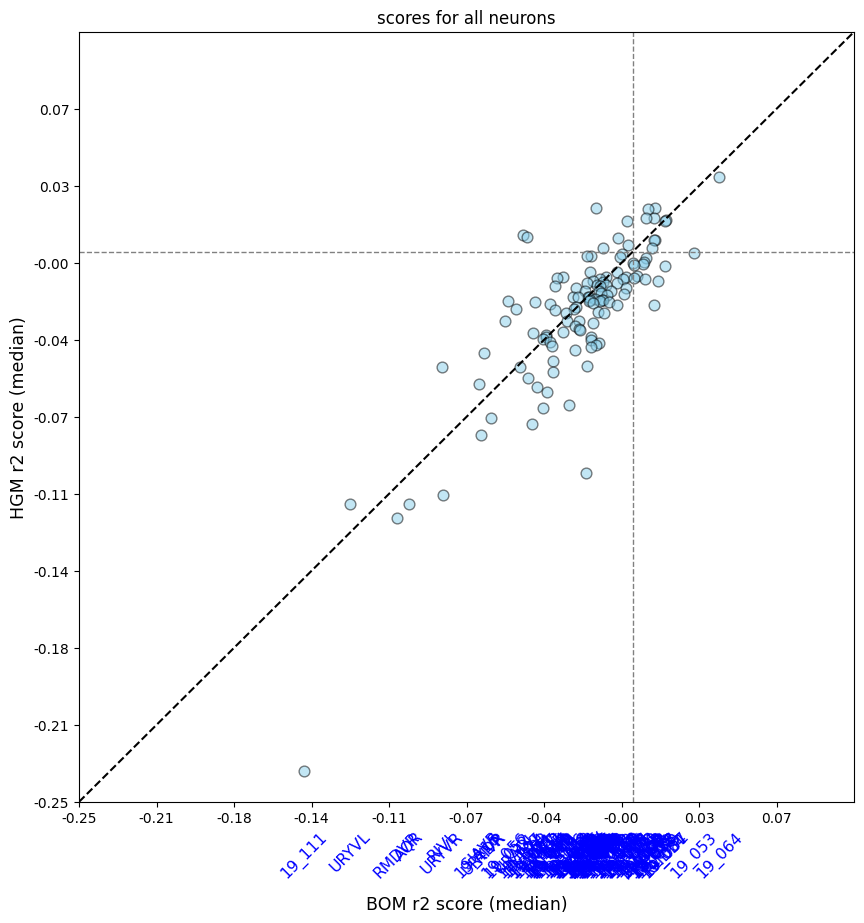

In [21]:
plot_utils.plot_performance_plot(
	neuron_scores_per_shuffle[0], None,
	title='scores for all neurons', limits=(-0.25, 0.1, -0.25, 0.1), force_medians=False
)